# CA1 experiment 01: hue

Only **`hsv_h`** changes, from 0.015 to 0.5. The hue of every training image is shifted by up to half the colour wheel, so a bag can be any colour. Idea: the model cannot lean on a bag's exact colour.

**Everything else is identical to the baseline**, including the data split (a fixed seed, shared through one folder on this computer), the training seed, and `fliplr=0.0`. Section 4 checks this in code and stops if more than one setting differs.

Run the cells in order on your own GPU. Results are saved to `C:\C389_local\runs\CA1_experiments\`. The last cell compares every experiment run so far.

> **Running on your own computer.** This copy is for a local GPU, not Colab. Put the Roboflow export zip in `C:\C389_local\data\` and run the cells in order. Everything is written to `C:\C389_local\runs\CA1_experiments\`. If your folder is somewhere else, change `LOCAL_ROOT` in the first code cell.


---

## 1. Setup

In [1]:
LOCAL_ROOT = r"C:\C389_local"   # holds data\ (the Roboflow zip) and runs\ (everything the notebooks write)
ULTRALYTICS_VERSION = "8.4.120"   # pinned, as in Lesson 3
RUNNING_ON_COLAB = False

import glob
import importlib.metadata
import os

import torch

if not torch.cuda.is_available():
    raise RuntimeError("PyTorch cannot see the GPU. Install the CUDA build of PyTorch from pytorch.org, "
                       "then restart this notebook.")
print("GPU:", torch.cuda.get_device_name(0),
      "(%.1f GB)" % (torch.cuda.get_device_properties(0).total_memory / 1e9))
try:
    installed = importlib.metadata.version("ultralytics")
    if installed != ULTRALYTICS_VERSION:
        print("WARNING: ultralytics %s is installed, these notebooks were written for %s.\n"
              "         Run: pip install ultralytics==%s" % (installed, ULTRALYTICS_VERSION, ULTRALYTICS_VERSION))
except importlib.metadata.PackageNotFoundError:
    raise RuntimeError("Run: pip install ultralytics==%s roboflow" % ULTRALYTICS_VERSION)

# Windows notebooks can crash when data loading uses extra processes, so load in the main process there.
WORKERS = 0 if os.name == "nt" else 8
print("LOCAL_ROOT:", LOCAL_ROOT, "  workers:", WORKERS)

GPU: NVIDIA GeForce RTX 3060 (12.9 GB)
LOCAL_ROOT: C:\C389_local   workers: 0


In [2]:
import json
import os
import random
import re
import shutil
import time
import zipfile
from collections import Counter, defaultdict

import torch
from PIL import Image as PILImage
from ultralytics import YOLO

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

PROJECT_ROOT = LOCAL_ROOT

# One folder shared by all the experiment notebooks: the scene split, every run, every result.
EXP_ROOT = os.path.join(PROJECT_ROOT, "runs", "CA1_experiments")
os.makedirs(os.path.join(EXP_ROOT, "results"), exist_ok=True)
SPLIT_DIR = os.path.join(EXP_ROOT, "dataset_by_scene")
print("EXP_ROOT:", EXP_ROOT)

GPU: NVIDIA GeForce RTX 3060
EXP_ROOT: C:\C389_local\runs\CA1_experiments


---

## 2. The data

The first experiment notebook you run downloads the Roboflow version and splits it by scene. The others reuse that split from the same folder, so every experiment sees the same train, valid and test images.

Put the Roboflow export zip in `C:\C389_local\data\` if you have not run another experiment first (or paste the Roboflow code below to download instead). On this computer the zip is used and no key is needed. If you paste code instead, the key is asked for and never saved in the notebook.

In [3]:
import re
from getpass import getpass

ROBOFLOW_CODE = """
from roboflow import Roboflow
rf = Roboflow(api_key="")
project = rf.workspace("zameers-workspace-3jsij").project("c389-ydfur")
version = project.version(5)
dataset = version.download("yolo26")
"""

YOLO_FORMATS = ("yolov8", "yolo26", "yolov11", "yolov12", "yolov9", "yolov5")


def read_roboflow_code(code):
    """Workspace, project, version and format from Roboflow's code, or None."""
    if not code.strip():
        return None
    key = re.search(r"api_key\s*=\s*[\"']([^\"']*)[\"']", code)
    if key and key.group(1).strip():
        raise ValueError("The pasted code still holds your private API key. "
                         "Delete it so the line reads api_key=\"\", then run again.")
    found = {}
    for name, pattern in (("workspace", r"\.workspace\(\s*[\"']([^\"']+)[\"']"),
                          ("project", r"\.project\(\s*[\"']([^\"']+)[\"']"),
                          ("version", r"\.version\(\s*(\d+)\s*\)"),
                          ("format", r"\.download\(\s*[\"']([^\"']+)[\"']")):
        match = re.search(pattern, code)
        if not match:
            raise ValueError("No %s in the pasted code. Copy the whole block Roboflow "
                             "shows under Show download code." % name)
        found[name] = match.group(1)
    found["version"] = int(found["version"])
    if found["format"] not in YOLO_FORMATS:
        raise ValueError("The code downloads the %r format. Choose YOLOv8 and copy "
                         "the code again." % found["format"])
    return found


def roboflow_key():
    if RUNNING_ON_COLAB:
        try:
            from google.colab import userdata
            return userdata.get("ROBOFLOW_API_KEY").strip()
        except Exception:
            pass
    return getpass("Roboflow private API key: ").strip()

In [4]:
def read_class_names(yaml_path):
    """The ordered class list out of a Roboflow data.yaml (list, dict or block form)."""
    with open(yaml_path, encoding="utf-8") as handle:
        lines = handle.read().splitlines()
    for index, line in enumerate(lines):
        if not line.startswith("names:"):
            continue
        rest = line.split(":", 1)[1].strip()
        if rest.startswith("{"):
            pairs = [part.split(":", 1) for part in rest.strip("{}").split(",")]
            return [value.strip().strip("'\"") for _, value in sorted(pairs, key=lambda p: int(p[0]))]
        if rest:
            return [name.strip().strip("'\"") for name in rest.strip("[]").split(",")]
        names = []
        for following in lines[index + 1:]:
            text = following.strip()
            if not text:
                continue
            if not (following.startswith(" ") or following.startswith("-")):
                break
            names.append((text[1:] if text.startswith("-") else text.split(":", 1)[1]).strip().strip("'\""))
        return names
    raise ValueError("No names: line in %s" % yaml_path)

In [5]:
SPLIT_FOLDERS = {"train": "train", "val": "valid", "test": "test"}


def normalise_data_yaml(dataset_dir):
    """Rewrite data.yaml with an absolute path and plain split names."""
    yaml_path = os.path.join(dataset_dir, "data.yaml")
    class_names = read_class_names(yaml_path)   # read before the file is rewritten
    splits = ["%s: %s/images" % (key, folder) for key, folder in SPLIT_FOLDERS.items()
              if os.path.isdir(os.path.join(dataset_dir, folder, "images"))]
    if not any(line.startswith("train:") for line in splits):
        raise FileNotFoundError("No train/images folder under %s" % dataset_dir)
    with open(yaml_path, "w", encoding="utf-8") as handle:
        print("path:", dataset_dir.replace(os.sep, "/"), file=handle)
        for line in splits:
            print(line, file=handle)
        print("", file=handle)
        print("nc:", len(class_names), file=handle)
        print("names:", json.dumps(class_names), file=handle)
    return yaml_path

In [6]:
def instances_per_class(dataset_dir, split, class_names):
    """Annotated instances of every class in one split, zeros included."""
    counts = {name: 0 for name in class_names}
    label_dir = os.path.join(dataset_dir, split, "labels")
    if not os.path.isdir(label_dir):
        return counts
    for filename in sorted(os.listdir(label_dir)):
        if not filename.endswith(".txt"):
            continue
        with open(os.path.join(label_dir, filename), encoding="utf-8") as handle:
            for line in handle:
                if line.strip():
                    class_id = int(line.split()[0])
                    if class_id < len(class_names):
                        counts[class_names[class_id]] += 1
    return counts


def show_instances(dataset_dir, class_names):
    splits = ["train", "valid", "test"]
    table = {split: instances_per_class(dataset_dir, split, class_names) for split in splits}
    print("%-14s %7s %7s %7s %7s" % ("class", "train", "valid", "test", "total"))
    for name in class_names:
        row = [table[split][name] for split in splits]
        print("%-14s %7d %7d %7d %7d" % (name, row[0], row[1], row[2], sum(row)))
    left = sum(table[s]["luggage_left"] for s in splits)
    right = sum(table[s]["luggage_right"] for s in splits)
    print("")
    print("luggage_left : luggage_right = %d : %d" % (left, right))
    if left and right and not 0.8 <= left / right <= 1.25:
        print("WARNING: the two luggage classes differ by more than 25 percent.")
    for split in splits:
        for name in LUGGAGE_CLASSES:
            if table[split][name] == 0:
                print("WARNING: %s has no instances in %s, so its score there means nothing."
                      % (name, split))
    return table

In [7]:
RESPLIT_BY_SCENE = True
VALID_FRACTION = 0.15
TEST_FRACTION = 0.15
SPLIT_SEED = 0
SCENE_RE = re.compile(r"_A(\d)_\d+_B(\d+)")   # angle and scene id in the file name
IMAGE_EXTS = (".jpg", ".jpeg", ".png")


def collect_images(dataset_dir):
    """Every (split, image path, label path) in the dataset."""
    rows = []
    for split in ("train", "valid", "test"):
        image_dir = os.path.join(dataset_dir, split, "images")
        if not os.path.isdir(image_dir):
            continue
        for name in sorted(os.listdir(image_dir)):
            if name.lower().endswith(IMAGE_EXTS):
                label = os.path.join(dataset_dir, split, "labels",
                                     os.path.splitext(name)[0] + ".txt")
                rows.append((split, os.path.join(image_dir, name), label))
    return rows


def scene_direction(label_paths, class_names):
    """The luggage class that dominates a scene's label files."""
    counts = Counter()
    for path in label_paths:
        if os.path.exists(path):
            with open(path, encoding="utf-8") as handle:
                for line in handle:
                    if line.strip():
                        name = class_names[int(line.split()[0])]
                        if name in LUGGAGE_CLASSES:
                            counts[name] += 1
    return counts.most_common(1)[0][0] if counts else "none"


def split_by_scene(dataset_dir, class_names, out_dir):
    """Copy the dataset to out_dir with whole scenes assigned to one split."""
    rows = collect_images(dataset_dir)
    scenes = defaultdict(list)
    keep = []
    for split, image, label in rows:
        match = SCENE_RE.search(os.path.basename(image))
        if match:
            scenes[(int(match.group(1)), int(match.group(2)))].append((image, label))
        else:
            keep.append((split, image, label))

    by_direction = defaultdict(list)
    for scene, files in scenes.items():
        by_direction[scene_direction([lab for _, lab in files], class_names)].append(scene)

    assignment = {}
    rng = random.Random(SPLIT_SEED)
    for direction, group in by_direction.items():
        group = sorted(group)
        rng.shuffle(group)
        total = sum(len(scenes[s]) for s in group)
        goal = {"valid": VALID_FRACTION * total, "test": TEST_FRACTION * total}
        have = {"valid": 0, "test": 0}
        for scene in group:
            size = len(scenes[scene])
            if have["valid"] < goal["valid"]:
                assignment[scene] = "valid"; have["valid"] += size
            elif have["test"] < goal["test"]:
                assignment[scene] = "test"; have["test"] += size
            else:
                assignment[scene] = "train"

    shutil.rmtree(out_dir, ignore_errors=True)
    for split in ("train", "valid", "test"):
        os.makedirs(os.path.join(out_dir, split, "images"))
        os.makedirs(os.path.join(out_dir, split, "labels"))

    def put(split, image, label):
        shutil.copy(image, os.path.join(out_dir, split, "images", os.path.basename(image)))
        if os.path.exists(label):
            shutil.copy(label, os.path.join(out_dir, split, "labels", os.path.basename(label)))

    for split, image, label in keep:
        put(split, image, label)
    for scene, files in scenes.items():
        for image, label in files:
            put(assignment[scene], image, label)

    with open(os.path.join(out_dir, "data.yaml"), "w", encoding="utf-8") as handle:
        print("path:", out_dir.replace(os.sep, "/"), file=handle)
        print("train: train/images", file=handle)
        print("val: valid/images", file=handle)
        print("test: test/images", file=handle)
        print("", file=handle)
        print("nc:", len(class_names), file=handle)
        print("names:", json.dumps(class_names), file=handle)
    return assignment, scenes

In [8]:
REQUIRE_PERSON_CLASSES = True
BASELINE_CLASSES = ["person_left", "person_right"]
LUGGAGE_CLASSES = ["luggage_left", "luggage_right"]

if os.path.exists(os.path.join(SPLIT_DIR, "data.yaml")):
    # Written by whichever experiment notebook ran first. Reusing it guarantees that every
    # experiment trains and is scored on exactly the same images.
    print("Reusing the scene split already on Drive:", SPLIT_DIR)
else:
    raw_dir = os.path.join(EXP_ROOT, "roboflow_download")
    local_zips = sorted(glob.glob(os.path.join(LOCAL_ROOT, "data", "*.zip")))
    if local_zips:
        # The Roboflow export you downloaded, put in C:\\C389_local\\data. No download, no key.
        print("Using the dataset zip:", local_zips[0])
        shutil.rmtree(raw_dir, ignore_errors=True)
        with zipfile.ZipFile(local_zips[0]) as archive:
            archive.extractall(raw_dir)

        class export:
            location = raw_dir
    else:
        ROBOFLOW = read_roboflow_code(ROBOFLOW_CODE)
        if not ROBOFLOW:
            raise ValueError("Put the Roboflow export zip in %s, or paste the download code above."
                             % os.path.join(LOCAL_ROOT, "data"))
        from roboflow import Roboflow
        project = Roboflow(api_key=roboflow_key()).workspace(ROBOFLOW["workspace"]).project(ROBOFLOW["project"])
        export = project.version(ROBOFLOW["version"]).download(ROBOFLOW["format"], location=raw_dir, overwrite=True)
    normalise_data_yaml(export.location)
    raw_classes = read_class_names(os.path.join(export.location, "data.yaml"))
    required = LUGGAGE_CLASSES + (BASELINE_CLASSES if REQUIRE_PERSON_CLASSES else [])
    missing = [n for n in required if n not in raw_classes]
    if missing:
        raise ValueError("Classes missing from the dataset: %s. Found: %s" % (missing, raw_classes))
    split_by_scene(export.location, raw_classes, SPLIT_DIR)

DATASET_DIR = SPLIT_DIR
DATA_YAML = os.path.join(DATASET_DIR, "data.yaml")
CLASS_NAMES = read_class_names(DATA_YAML)
print("classes:", CLASS_NAMES)
show_instances(DATASET_DIR, CLASS_NAMES)

Reusing the scene split already on Drive: C:\C389_local\runs\CA1_experiments\dataset_by_scene
classes: ['luggage_left', 'luggage_right', 'person_left', 'person_right']
class            train   valid    test   total
luggage_left       244      58      56     358
luggage_right      244      62      54     360
person_left        180      40      22     242
person_right       197      65      42     304

luggage_left : luggage_right = 358 : 360


{'train': {'luggage_left': 244,
  'luggage_right': 244,
  'person_left': 180,
  'person_right': 197},
 'valid': {'luggage_left': 58,
  'luggage_right': 62,
  'person_left': 40,
  'person_right': 65},
 'test': {'luggage_left': 56,
  'luggage_right': 54,
  'person_left': 22,
  'person_right': 42}}

---

## 3. The one change

`BASELINE` is the same dictionary in every experiment notebook. `CONFIG` copies it and changes exactly the setting named in the title.

In [9]:
BASELINE = {"model": "yolo26n.pt", "epochs": 100, "imgsz": 640, "batch": 16, "hsv_h": 0.015, "hsv_s": 0.7, "hsv_v": 0.4, "bgr": 0.0}
CHANGE = {"hsv_h": 0.5}            # the ONE thing this experiment changes
CONFIG = {**BASELINE, **CHANGE}
CHANGED = ", ".join(k for k in BASELINE if CONFIG[k] != BASELINE[k]) or "nothing (baseline)"

differing = [k for k in BASELINE if CONFIG[k] != BASELINE[k]]
if len(differing) > 1:
    raise ValueError("More than one setting differs from the baseline: %s. Change one at a time." % differing)

print("%-8s %-12s %-12s" % ("setting", "baseline", "this run"))
for key in BASELINE:
    flag = "   <-- changed" if CONFIG[key] != BASELINE[key] else ""
    print("%-8s %-12s %-12s%s" % (key, BASELINE[key], CONFIG[key], flag))
print("fliplr   0.0          0.0            (never changes: a flip turns left into right)")

setting  baseline     this run    
model    yolo26n.pt   yolo26n.pt  
epochs   100          100         
imgsz    640          640         
batch    16           16          
hsv_h    0.015        0.5            <-- changed
hsv_s    0.7          0.7         
hsv_v    0.4          0.4         
bgr      0.0          0.0         
fliplr   0.0          0.0            (never changes: a flip turns left into right)


---

## 4. Training

In [10]:
started = time.time()
model = YOLO(CONFIG["model"])
model.train(
    data=DATA_YAML,
    epochs=CONFIG["epochs"],
    imgsz=CONFIG["imgsz"],
    batch=CONFIG["batch"],
    fliplr=0.0,                       # must stay 0.0
    hsv_h=CONFIG["hsv_h"],
    hsv_s=CONFIG["hsv_s"],
    hsv_v=CONFIG["hsv_v"],
    bgr=CONFIG["bgr"],
    project=EXP_ROOT,
    name='hue',
    exist_ok=True,
    seed=0,
    workers=WORKERS,
)
TRAIN_MINUTES = round((time.time() - started) / 60, 1)
print("training took %.1f minutes" % TRAIN_MINUTES)

New https://pypi.org/project/ultralytics/8.4.207 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\C389_local\runs\CA1_experiments\dataset_by_scene\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.5, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_r

---

## 5. Scoring

The same three tests for every experiment: the validation images, the test images, and the test images with the colour removed. mAP@.5:.95 is the stricter measure and the one with room to move.

In [11]:
EXP_NAME = 'hue'
EXP_ID = '01_hue'
RUN_DIR = os.path.join(EXP_ROOT, EXP_NAME)
BEST_WEIGHTS = os.path.join(RUN_DIR, "weights", "best.pt")
IMAGE_EXTS = (".jpg", ".jpeg", ".png")

# The test photos with the colour removed, to see how much each run leans on colour.
TEST_FOLDER = "test" if os.path.isdir(os.path.join(DATASET_DIR, "test", "images")) else "valid"
TEST_SPLIT = "test" if TEST_FOLDER == "test" else "val"
GREY_SET = os.path.join(EXP_ROOT, "test_greyscale")
GREY_YAML = os.path.join(GREY_SET, "data.yaml")
if not os.path.exists(GREY_YAML):
    os.makedirs(os.path.join(GREY_SET, "images")); os.makedirs(os.path.join(GREY_SET, "labels"))
    src_images = os.path.join(DATASET_DIR, TEST_FOLDER, "images")
    for name in os.listdir(src_images):
        if name.lower().endswith(IMAGE_EXTS):
            stem = os.path.splitext(name)[0]
            PILImage.open(os.path.join(src_images, name)).convert("L").convert("RGB").save(
                os.path.join(GREY_SET, "images", stem + ".jpg"), quality=95)
            label = os.path.join(DATASET_DIR, TEST_FOLDER, "labels", stem + ".txt")
            if os.path.exists(label):
                shutil.copy(label, os.path.join(GREY_SET, "labels", stem + ".txt"))
    with open(GREY_YAML, "w", encoding="utf-8") as handle:
        print("path:", GREY_SET.replace(os.sep, "/"), file=handle)
        print("train: images\nval: images\ntest: images", file=handle)
        print("nc:", len(CLASS_NAMES), file=handle)
        print("names:", json.dumps(CLASS_NAMES), file=handle)


def score(weights, data, split):
    m = YOLO(weights).val(data=data, split=split, verbose=False, workers=WORKERS)
    out = {"precision": float(m.box.mp), "recall": float(m.box.mr),
           "map50": float(m.box.map50), "map": float(m.box.map)}
    for i, class_id in enumerate(m.ap_class_index):
        out["map_" + CLASS_NAMES[int(class_id)]] = float(m.box.ap[i])   # per class mAP@.5:.95
    return out


result = {
    "experiment": EXP_NAME,
    "changed": CHANGED,
    "config": CONFIG,
    "train_minutes": TRAIN_MINUTES,
    "valid": score(BEST_WEIGHTS, DATA_YAML, "val"),
    "test": score(BEST_WEIGHTS, DATA_YAML, TEST_SPLIT),
    "test_greyscale": score(BEST_WEIGHTS, GREY_YAML, "val"),
}
with open(os.path.join(EXP_ROOT, "results", EXP_NAME + ".json"), "w", encoding="utf-8") as handle:
    json.dump(result, handle, indent=1)

print("%-22s %9s %9s %9s %9s" % ("", "precision", "recall", "mAP@.5", "mAP@.5:.95"))
for split in ("valid", "test", "test_greyscale"):
    r = result[split]
    print("%-22s %9.3f %9.3f %9.3f %9.3f" % (split, r["precision"], r["recall"], r["map50"], r["map"]))
print("")
print("luggage_left  test mAP@.5:.95: %.3f" % result["test"].get("map_luggage_left", 0))
print("luggage_right test mAP@.5:.95: %.3f" % result["test"].get("map_luggage_right", 0))
print("saved to", os.path.join(EXP_ROOT, "results", EXP_NAME + ".json"))

Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 185.6120.3 MB/s, size: 42.4 KB)
val: Scanning C:\C389_local\runs\CA1_experiments\dataset_by_scene\valid\labels.cache... 131 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 131/131  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 5.1it/s 1.8s0.2s
                   all        131        225      0.947      0.943      0.977      0.788
Speed: 0.9ms preprocess, 4.3ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to C:\C389_local\notebooks\runs\detect\val-4
Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, r

---

## 5b. Curves and confusion matrices for this run

The training curves show whether the run was still improving at the end. The precision-recall curve and the confusion matrix show where it goes wrong: a box missed, a box with nothing there, or left mistaken for right. The test confusion matrix is made here, so run this cell before the charts at the end.

Training curves (loss, precision, recall, mAP per epoch)


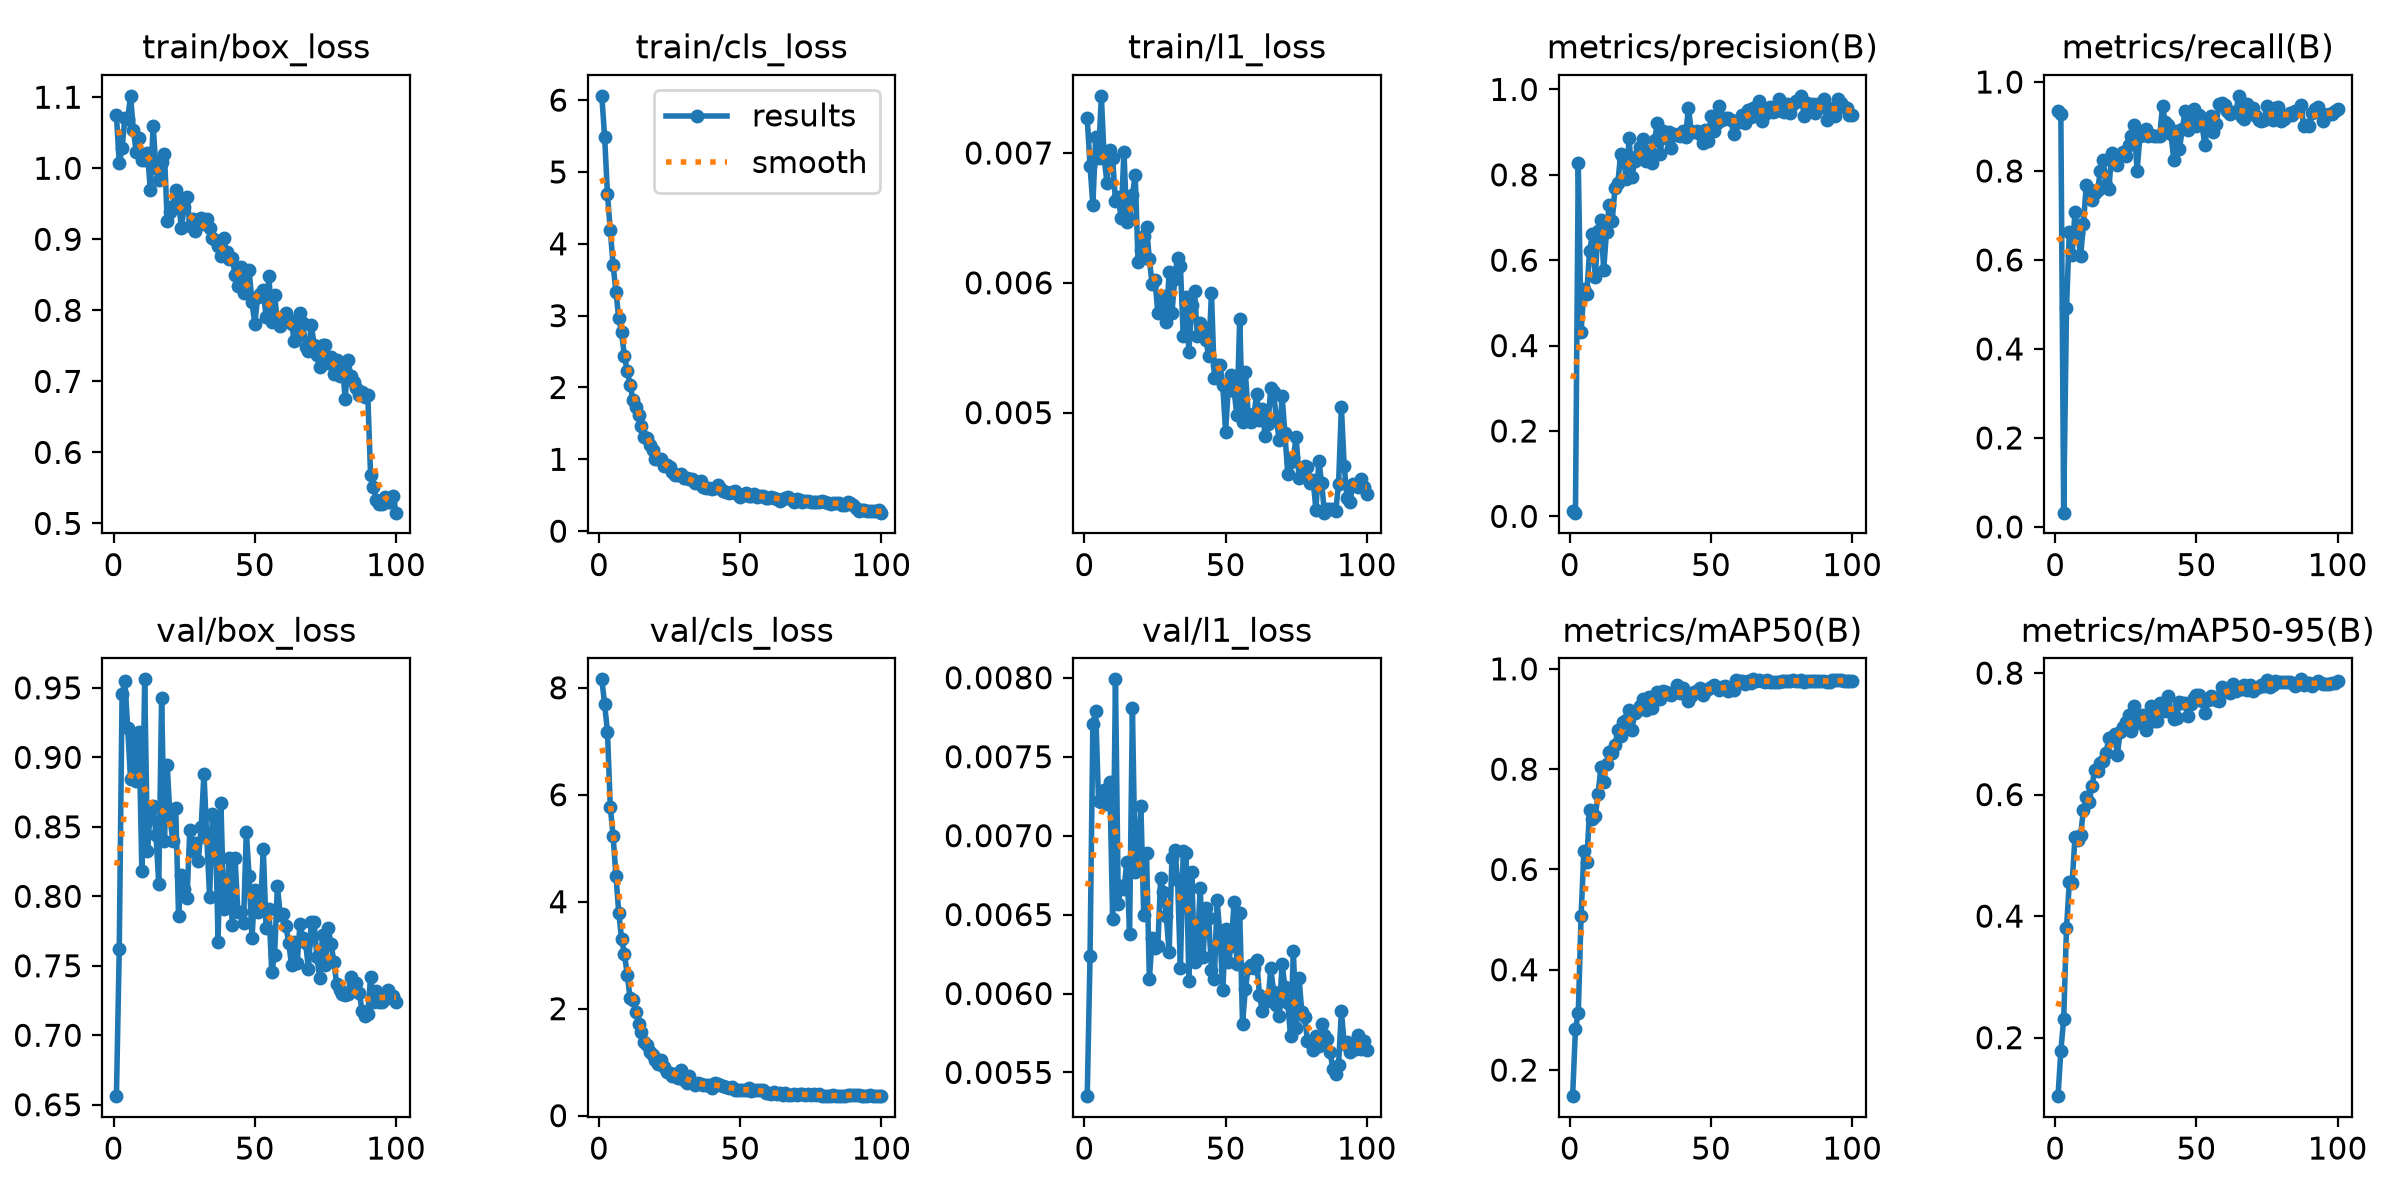

Precision-recall curve per class, valid set


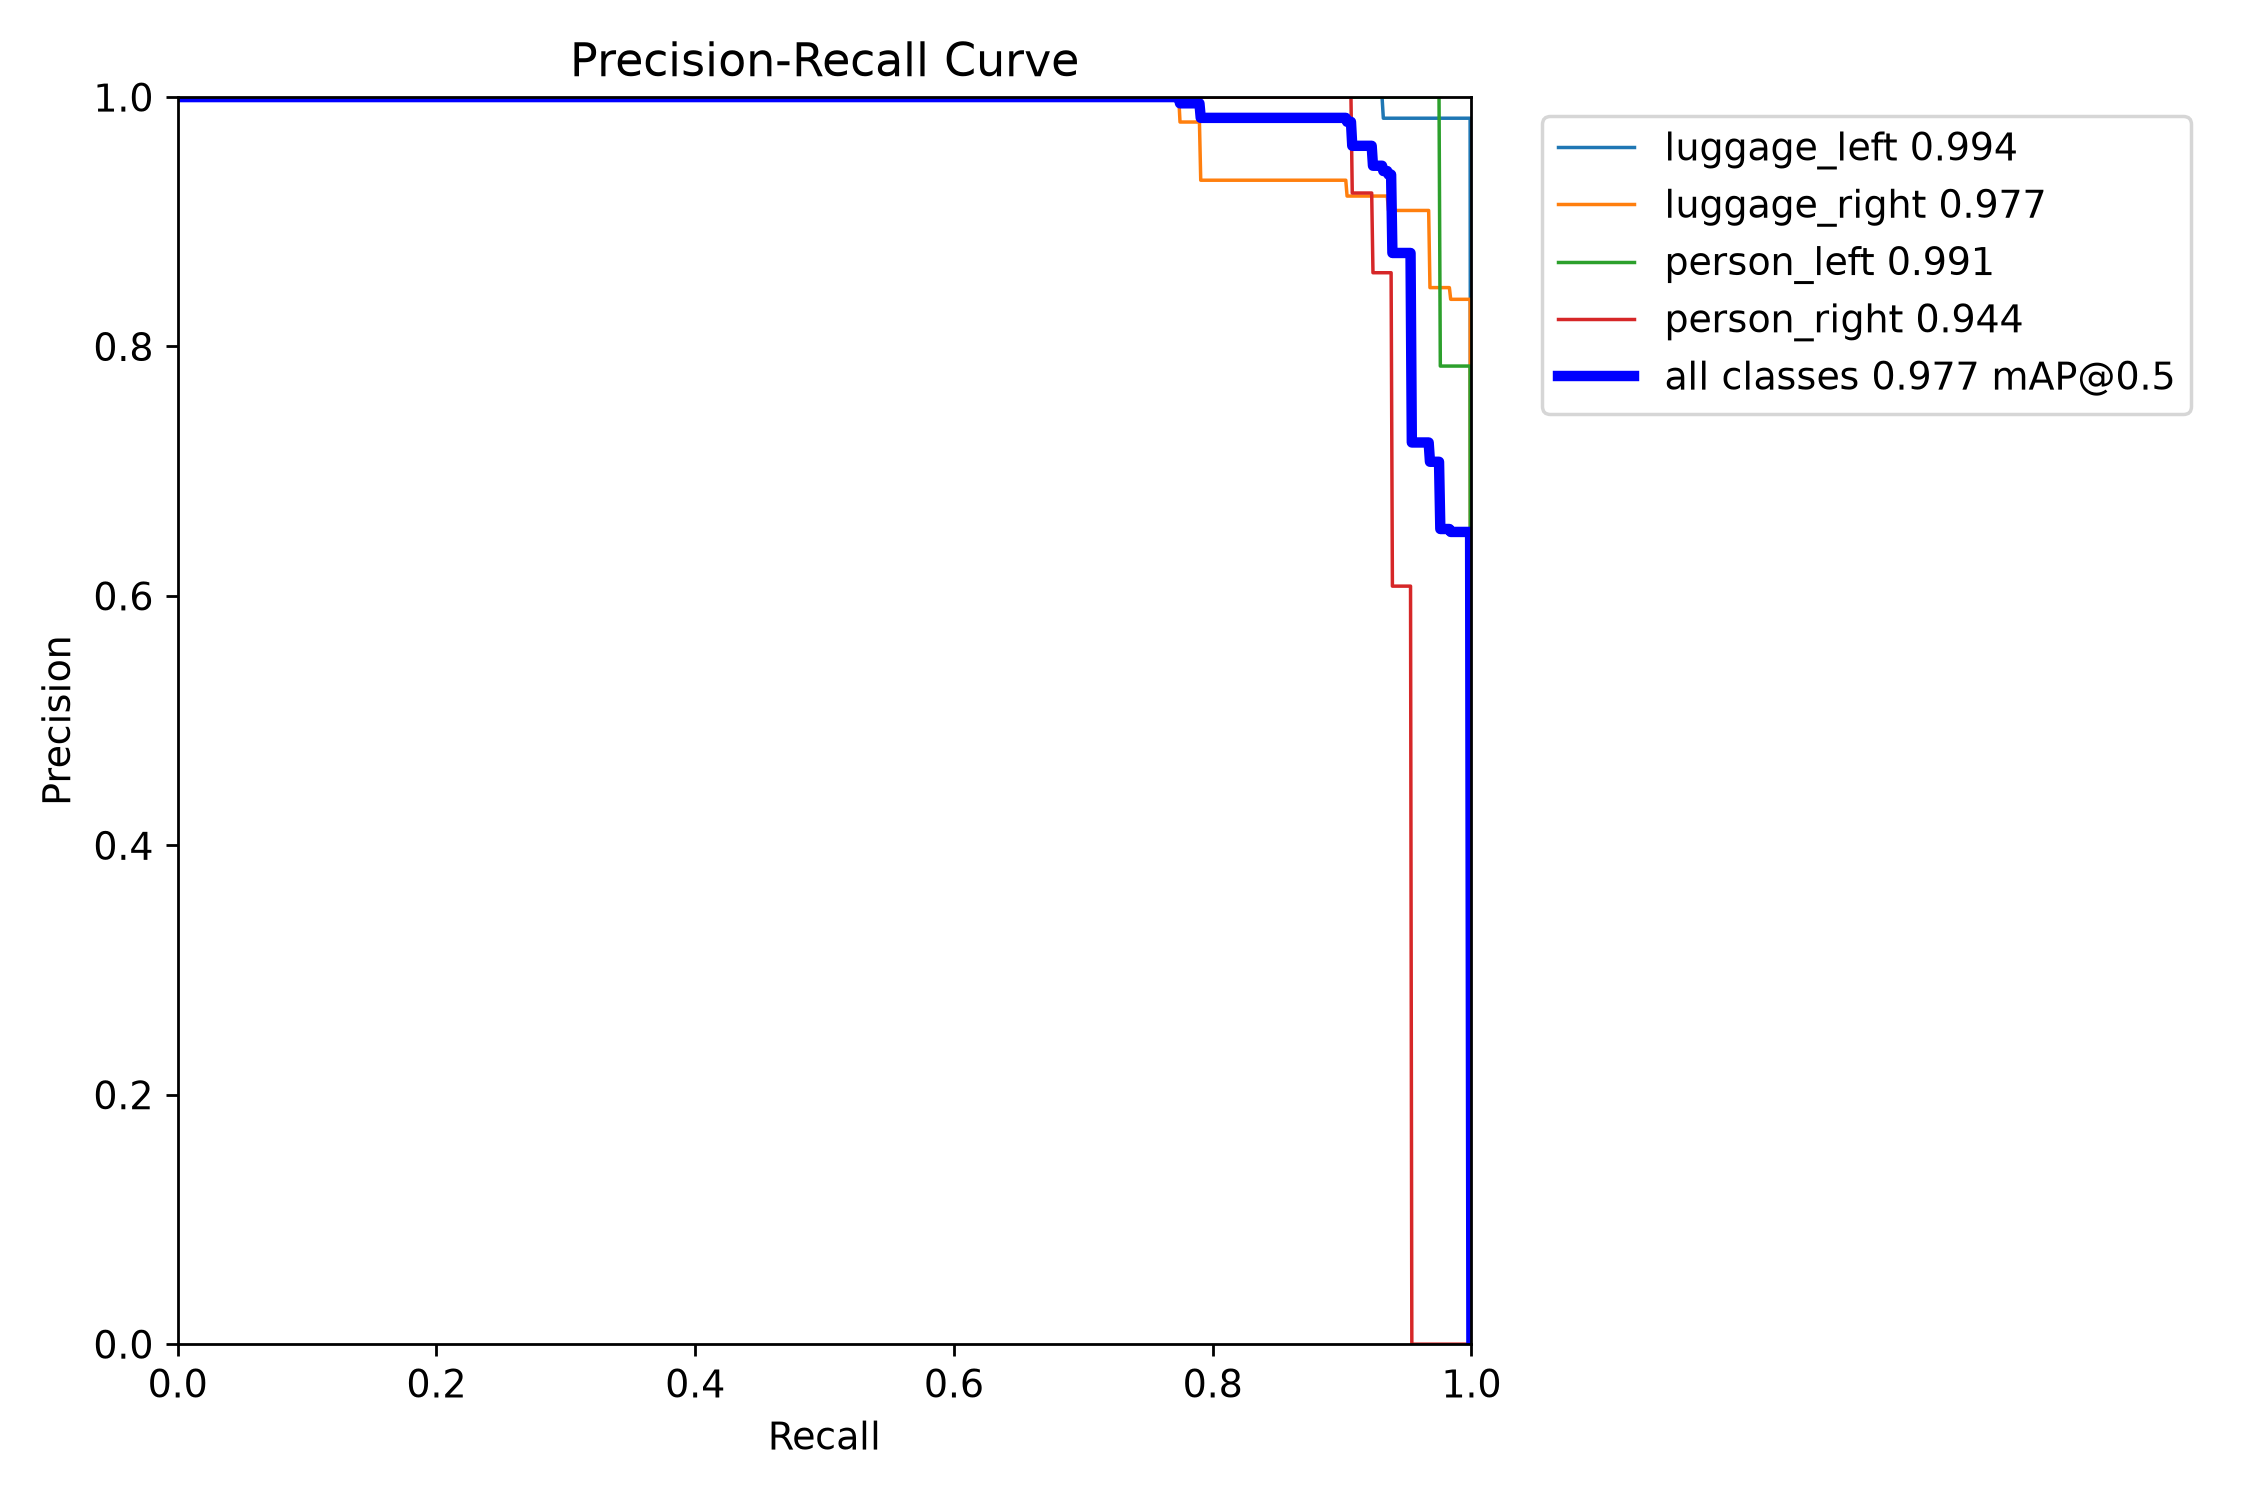

Confusion matrix, valid set


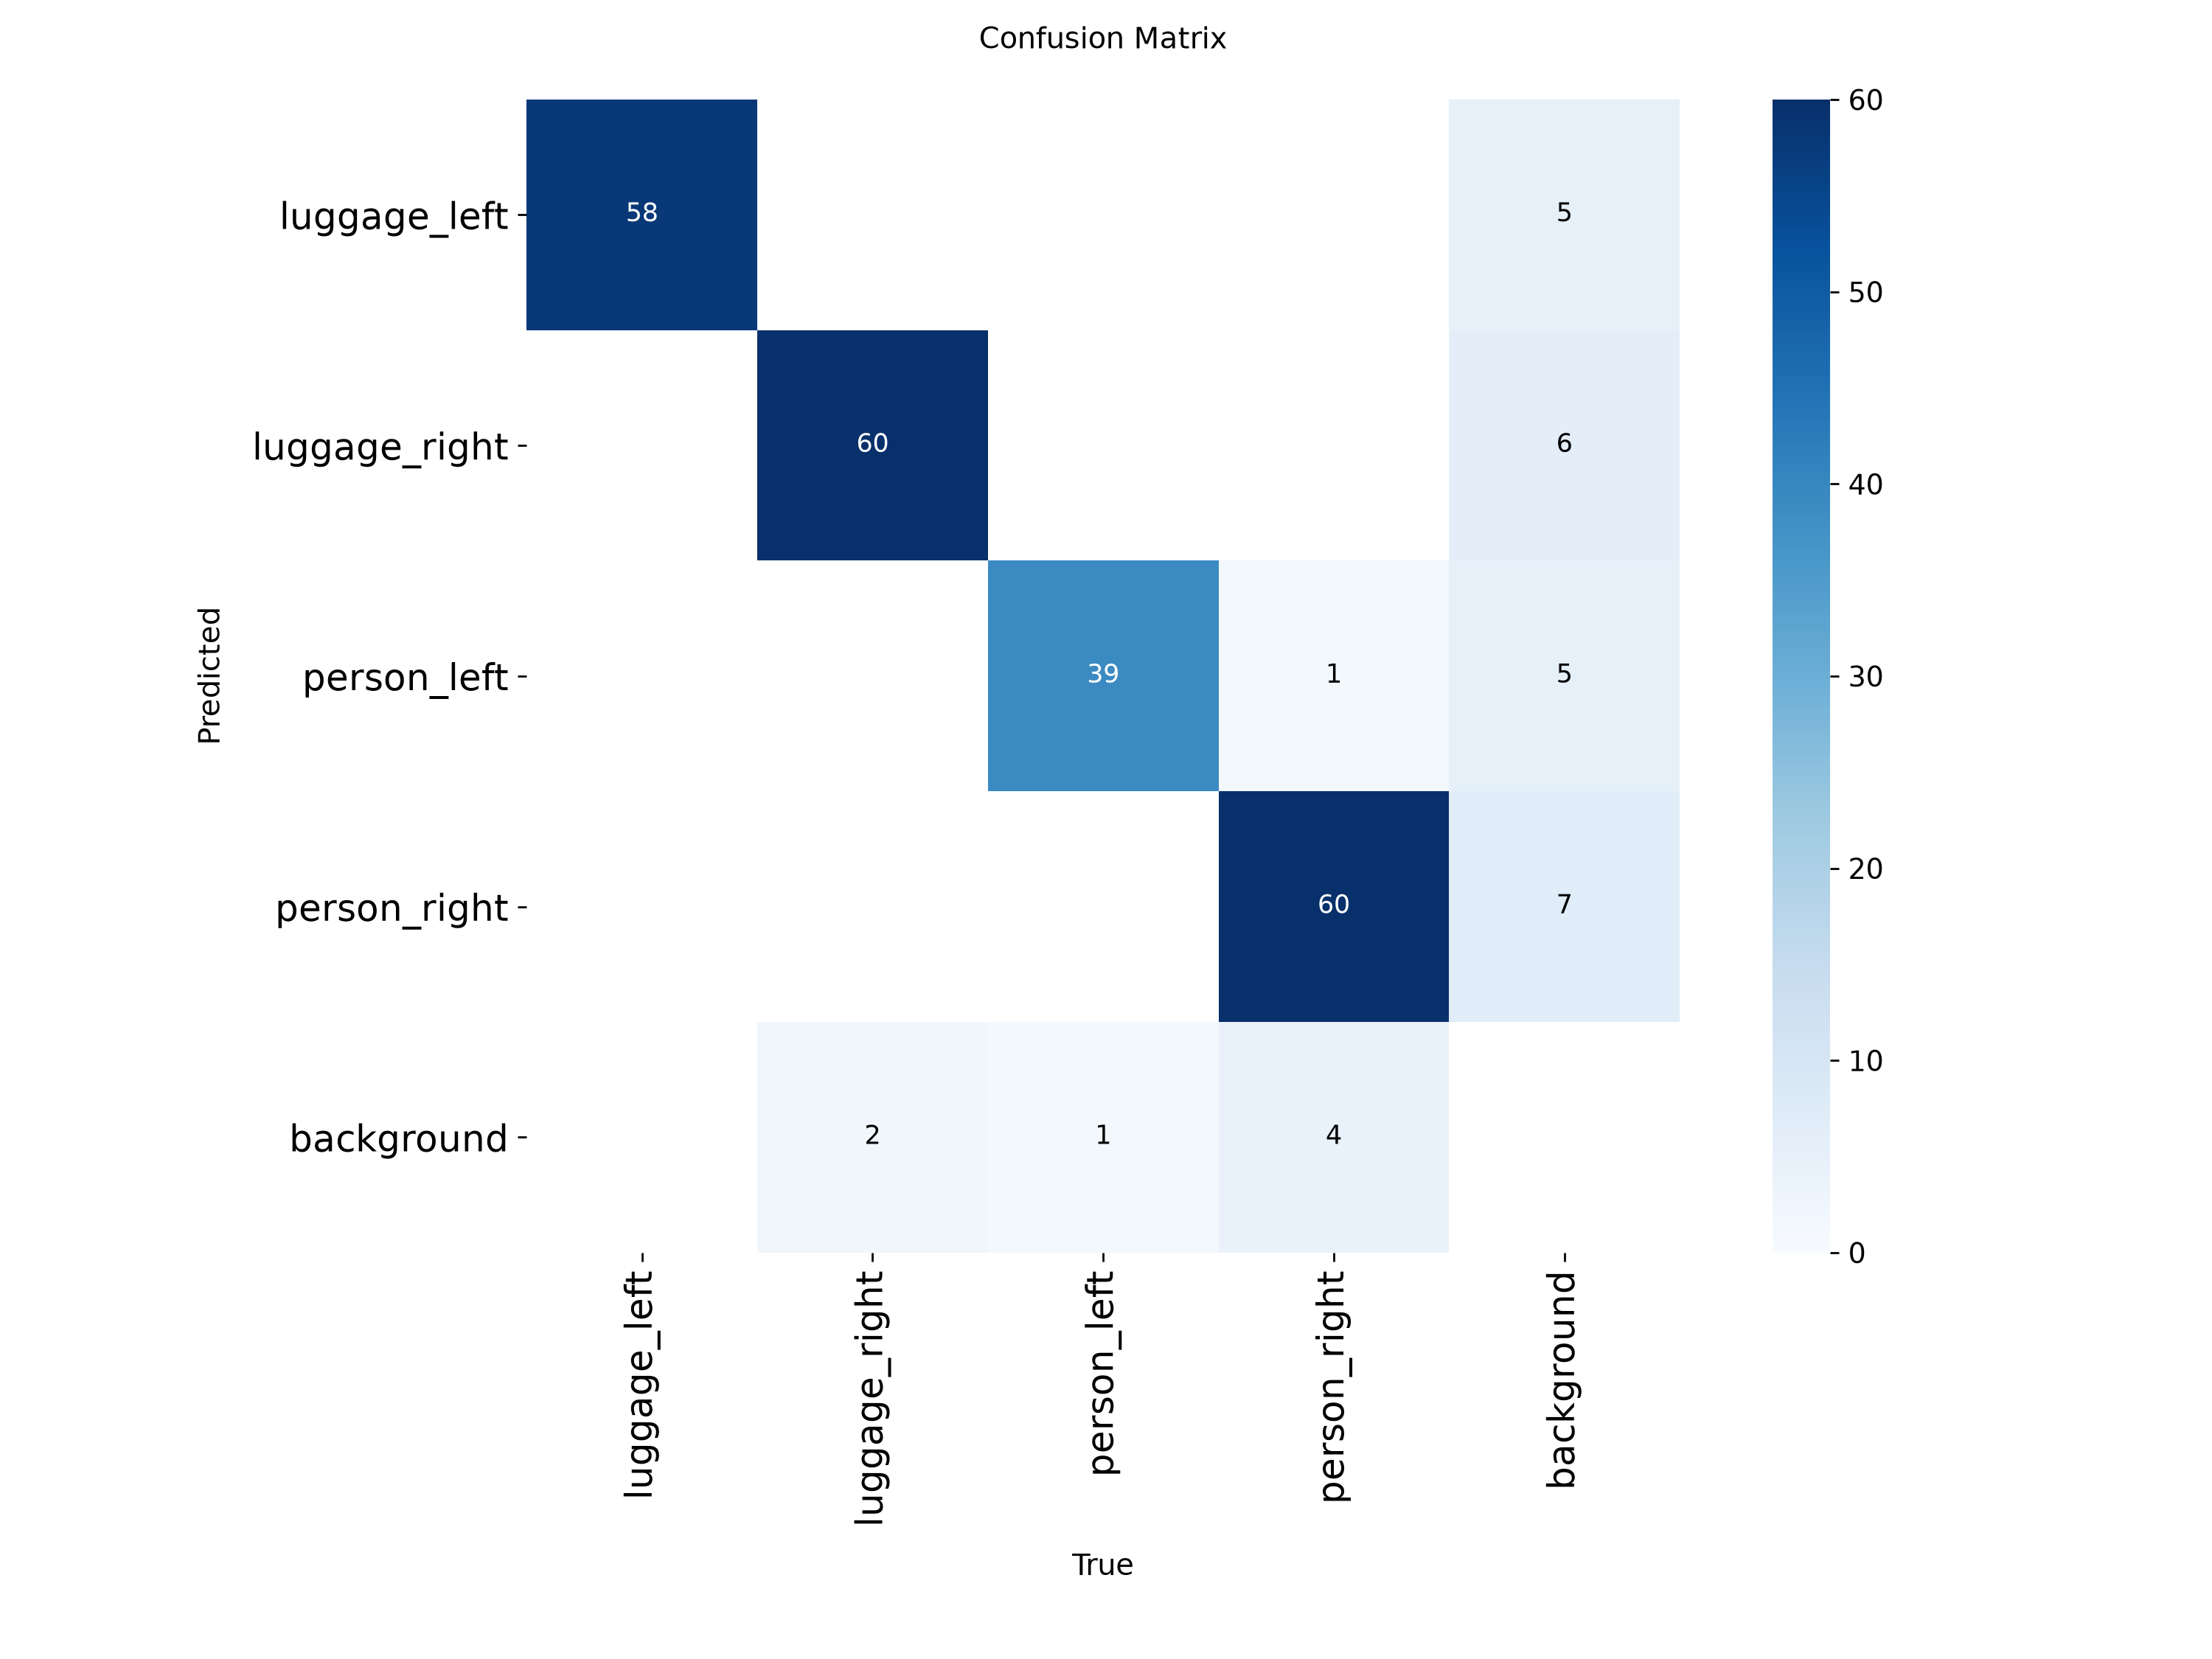

Ultralytics 8.4.120  Python-3.12.0 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 304.748.8 MB/s, size: 40.9 KB)
val: Scanning C:\C389_local\runs\CA1_experiments\dataset_by_scene\test\labels.cache... 96 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 96/96  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.6it/s 1.7s0.3s
                   all         96        174      0.948      0.971      0.992      0.803
Speed: 0.7ms preprocess, 6.0ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to C:\C389_local\runs\CA1_experiments\hue\test_eval
Precision-recall curve per class, test set


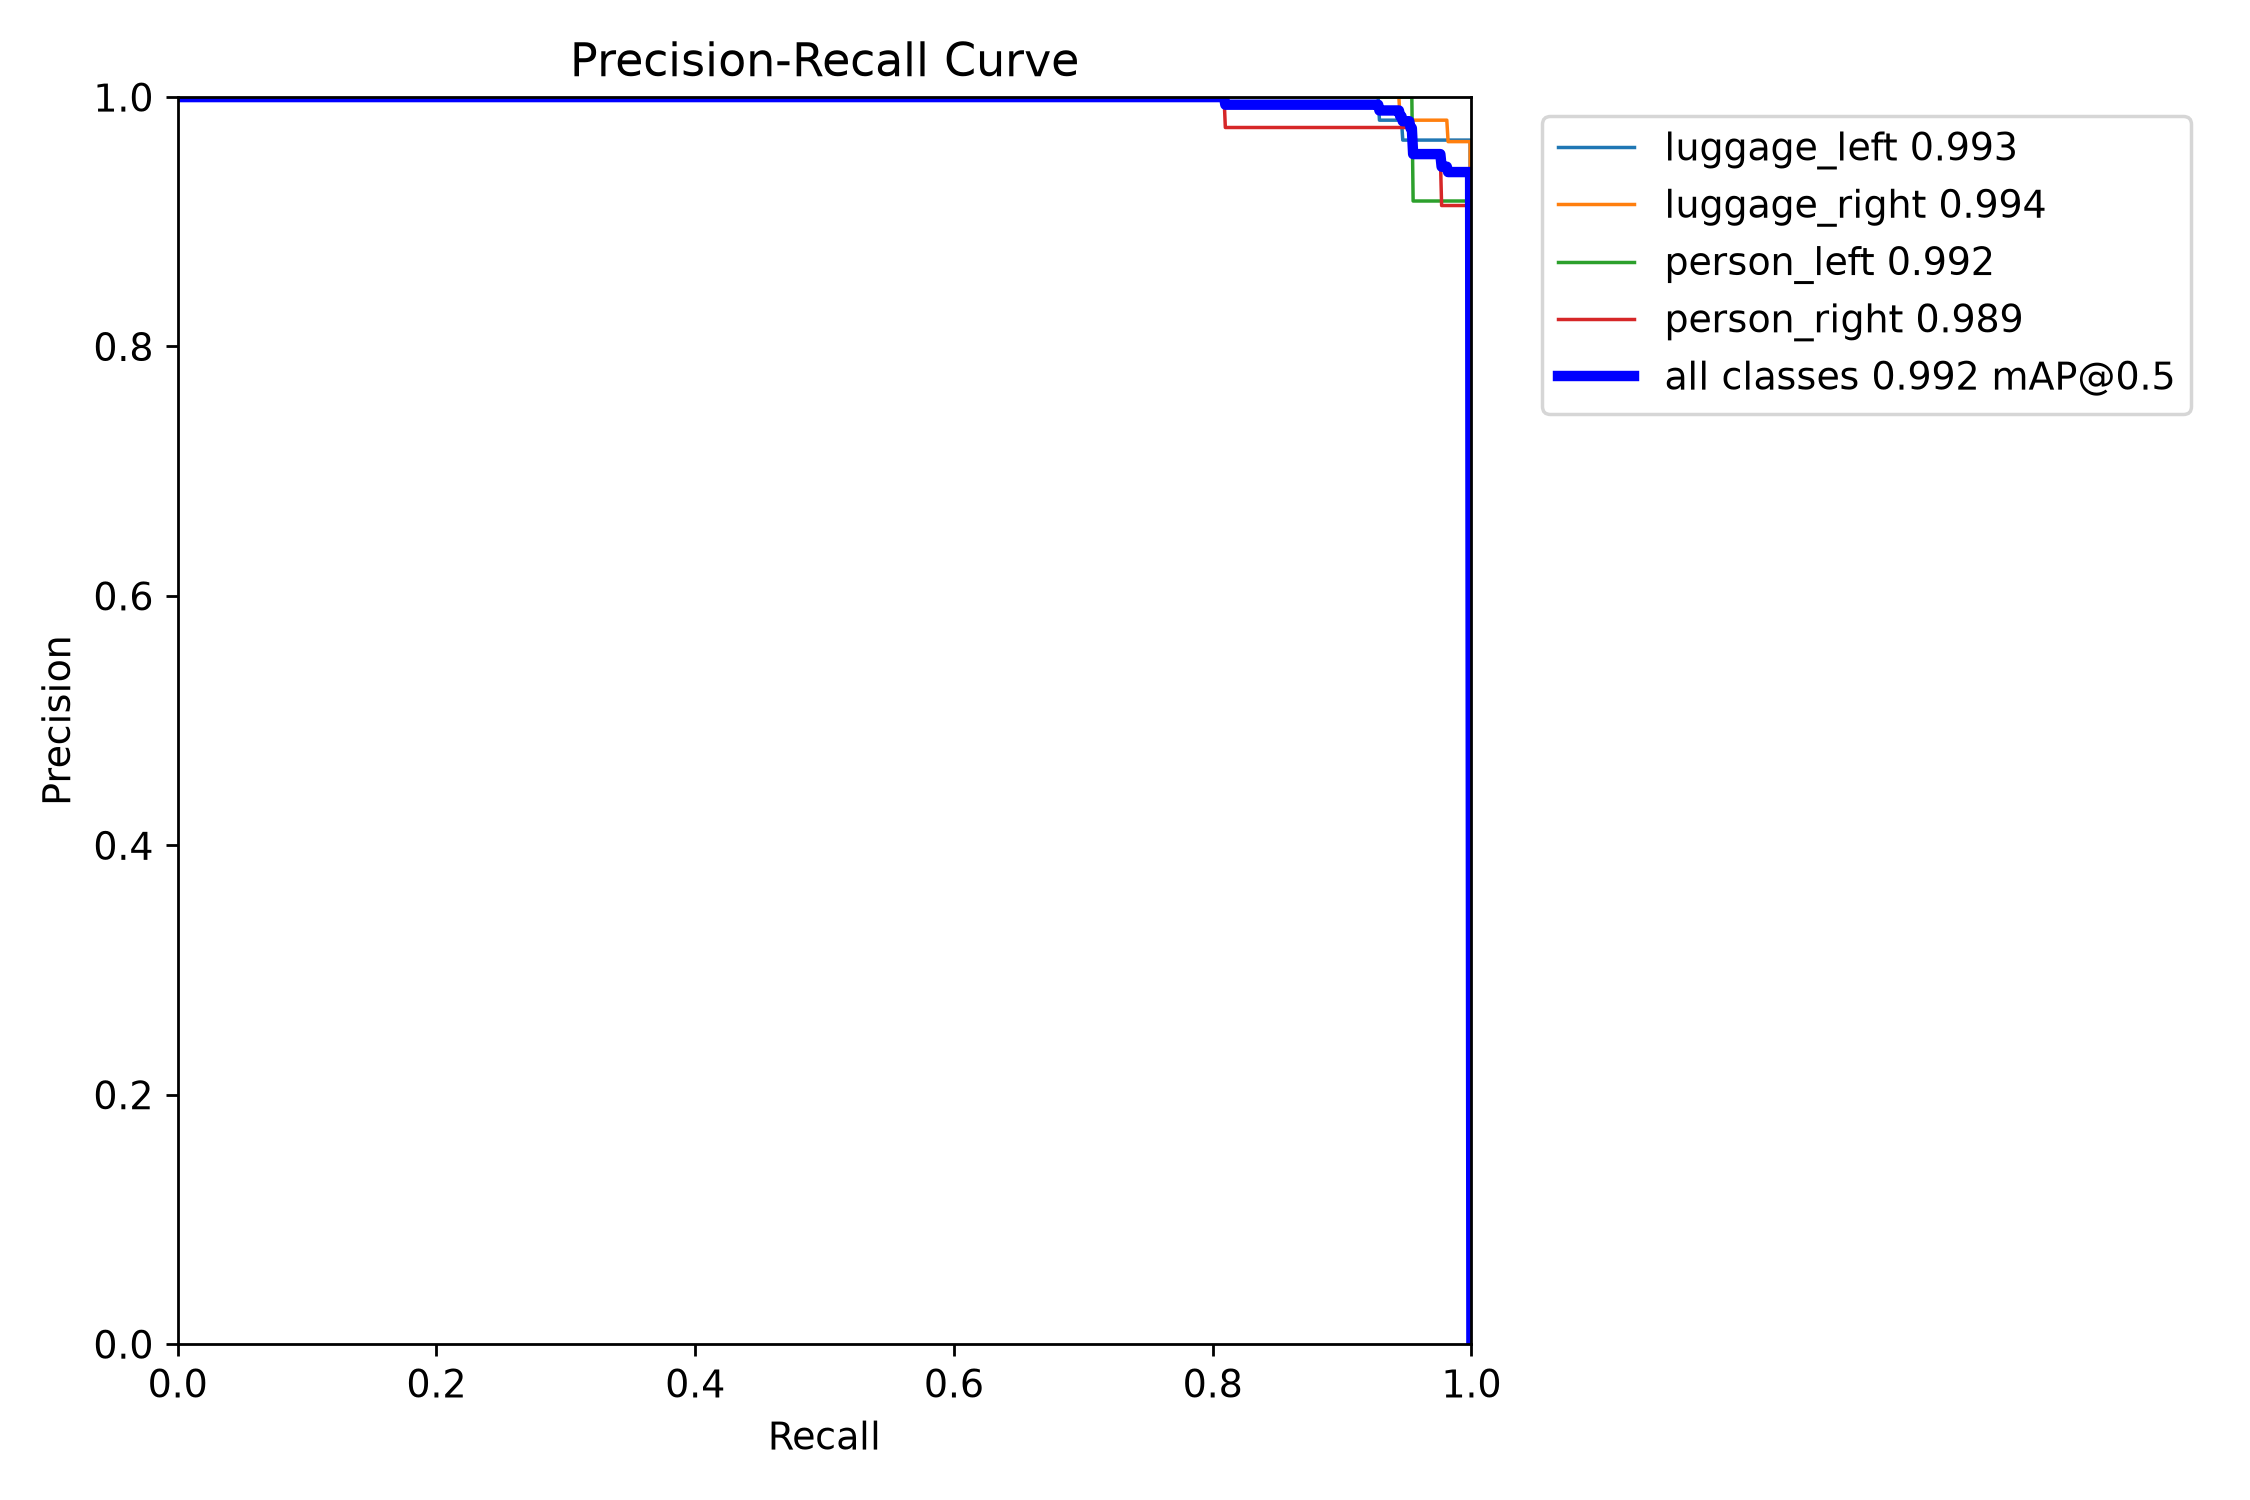

Confusion matrix, test set


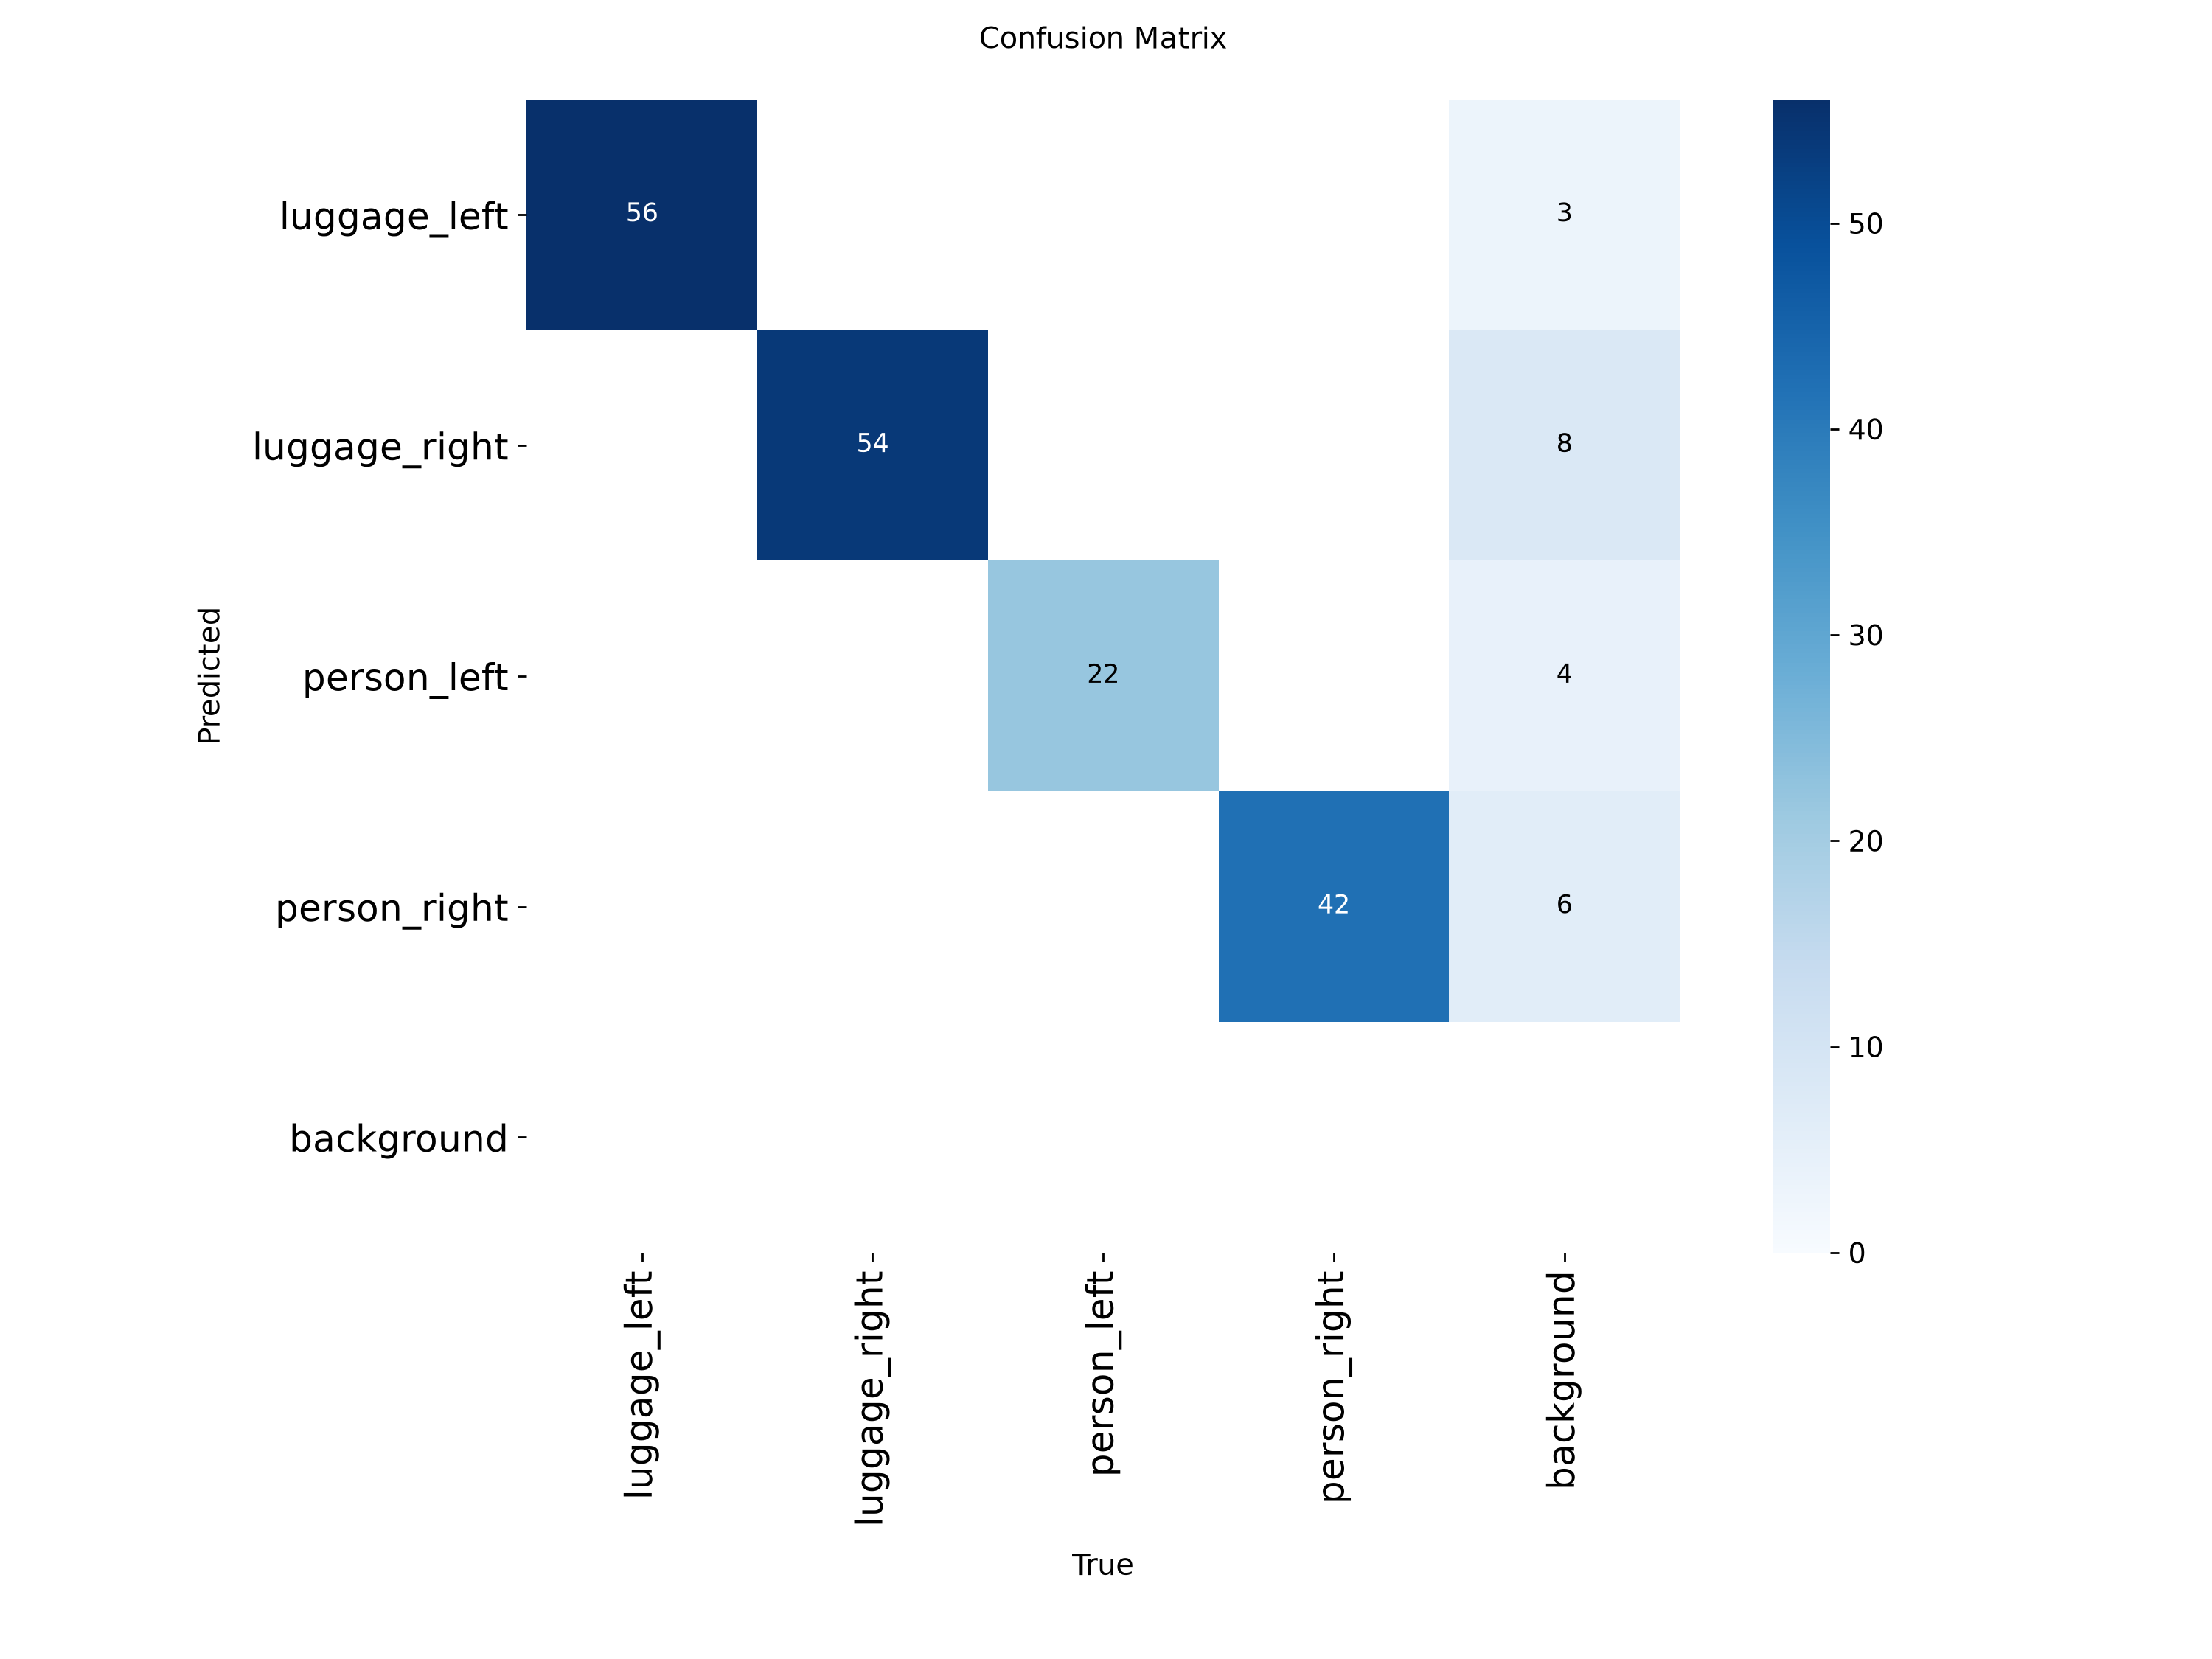

In [12]:
# The pictures for this run: training curves, precision-recall curve, confusion matrices.
from IPython.display import display, Image as IPImage

def show(path, title):
    print(title)
    if os.path.exists(path):
        display(IPImage(filename=path, width=820))
    else:
        print("  (not found: %s)" % path)

# Saved by Ultralytics at the end of training, on the validation images.
show(os.path.join(RUN_DIR, "results.png"), "Training curves (loss, precision, recall, mAP per epoch)")
show(os.path.join(RUN_DIR, "BoxPR_curve.png"), "Precision-recall curve per class, valid set")
show(os.path.join(RUN_DIR, "confusion_matrix.png"), "Confusion matrix, valid set")

# The same two pictures for the TEST images, made now.
YOLO(BEST_WEIGHTS).val(data=DATA_YAML, split=TEST_SPLIT, plots=True, project=RUN_DIR,
                       name="test_eval", exist_ok=True, verbose=False, workers=WORKERS)
show(os.path.join(RUN_DIR, "test_eval", "BoxPR_curve.png"), "Precision-recall curve per class, test set")
show(os.path.join(RUN_DIR, "test_eval", "confusion_matrix.png"), "Confusion matrix, test set")

---

## 6. All experiments so far

In [13]:
# Every experiment finished so far, side by side, from the files each notebook saved.
results_dir = os.path.join(EXP_ROOT, "results")
runs = {}
for name in sorted(os.listdir(results_dir)):
    if name.endswith(".json"):
        with open(os.path.join(results_dir, name), encoding="utf-8") as handle:
            runs[name[:-5]] = json.load(handle)

print("%-18s %-14s %9s %9s %9s %9s %9s %6s" % ("run", "changed", "valid", "test", "test", "test L", "test R", "test"))
print("%-18s %-14s %9s %9s %9s %9s %9s %6s" % ("", "", "mAP.5:.95", "mAP.5", "mAP.5:.95", "mAP.5:.95", "mAP.5:.95", "grey"))
for name, r in runs.items():
    t = r["test"]
    print("%-18s %-14s %9.3f %9.3f %9.3f %9.3f %9.3f %6.3f"
          % (name, r["changed"], r["valid"]["map"], t["map50"], t["map"],
             t.get("map_luggage_left", 0), t.get("map_luggage_right", 0), r["test_greyscale"]["map"]))

base = runs.get("baseline")
if base:
    print("")
    print("change against baseline          test mAP@.5:.95   greyscale test mAP@.5:.95")
    for name, r in runs.items():
        if name != "baseline":
            print("%-18s %-14s %+8.3f   %+8.3f" % (name, r["changed"], r["test"]["map"] - base["test"]["map"],
                                                  r["test_greyscale"]["map"] - base["test_greyscale"]["map"]))
else:
    print("\nRun 00_baseline first: every change is measured against it.")
print("\nA gap under about 0.01 to 0.02 is noise on a test set this small.")

run                changed            valid      test      test    test L    test R   test
                                  mAP.5:.95     mAP.5 mAP.5:.95 mAP.5:.95 mAP.5:.95   grey
baseline           nothing (baseline)     0.793     0.989     0.793     0.816     0.782  0.695
hue                hsv_h              0.788     0.992     0.803     0.819     0.776  0.772

change against baseline          test mAP@.5:.95   greyscale test mAP@.5:.95
hue                hsv_h            +0.010     +0.076

A gap under about 0.01 to 0.02 is noise on a test set this small.


In [14]:
# Charts across every experiment run so far, from the saved result files.
import matplotlib.pyplot as plt
from matplotlib import image as mpimg

names = list(runs)
test_map = [runs[n]["test"]["map"] for n in names]
grey_map = [runs[n]["test_greyscale"]["map"] for n in names]
position = range(len(names))

fig, ax = plt.subplots(figsize=(max(6, 1.6 * len(names) + 2), 4))
ax.bar([p - 0.2 for p in position], test_map, 0.4, label="test", color="#5E9E1F")
ax.bar([p + 0.2 for p in position], grey_map, 0.4, label="test, colour removed", color="#E8730C")
for p, a, b in zip(position, test_map, grey_map):
    ax.text(p - 0.2, a, "%.3f" % a, ha="center", va="bottom", fontsize=8)
    ax.text(p + 0.2, b, "%.3f" % b, ha="center", va="bottom", fontsize=8)
ax.set_xticks(list(position))
ax.set_xticklabels(names, rotation=20, ha="right")
ax.set_ylabel("mAP@.5:.95")
low = min(test_map + grey_map)
ax.set_ylim(max(0, low - 0.1), 1.0)
ax.set_title("Every experiment: test and colour-removed test")
ax.legend()
plt.tight_layout()
plt.show()

# Each run's confusion matrix on the test set, side by side.
shown = [n for n in names if os.path.exists(os.path.join(EXP_ROOT, n, "test_eval", "confusion_matrix.png"))]
if shown:
    columns = 2
    rows_n = (len(shown) + columns - 1) // columns
    fig, axes = plt.subplots(rows_n, columns, figsize=(7 * columns, 6 * rows_n))
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]
    for axis in axes:
        axis.axis("off")
    for axis, n in zip(axes, shown):
        axis.imshow(mpimg.imread(os.path.join(EXP_ROOT, n, "test_eval", "confusion_matrix.png")))
        axis.set_title(n)
    plt.tight_layout()
    plt.show()
else:
    print("No test confusion matrices yet: run section 5b in each experiment notebook.")

<Figure size 600x400 with 1 Axes>

<Figure size 1400x600 with 2 Axes>